# **PDAN8411 (VC ONLINE) - PART 1: LINEAR REGRESSION**
### ***ST1019837 - THULEDU TSHABALALA***
#### https://github.com/VCONLINE/vc-online-pdan8411-part1-2025-Thuledu

## **Please Note the Following:**
<li>1.Evaluating the dataset for suitability to apply a Linear Regression algorithm.</li>
<li>2.Analysis Plan.</li>
<li>5.Client Report.</li>
<p>The above mentioned 1, 2 and 5 are in one file that is separate to this one. <br>
This file used in Jupyter Notebook with Python code only consists of  of 3. Conducting the Analysis and 4. Model Evaluation</p>


# **3. Conducting the Analysis**
## **Medical Costs Personal Datasets**: Insurance Forecast using Linear Regression

In this analysis, we will explore the relationship between various medical costs and patient demographics, utilizing linear regression techniques to forecast insurance costs based on historical data.



#### **Download the dataset**

In [1]:
#!/bin/bash
!kaggle datasets download mirichoi0218/insurance
# (Choi, 2018)

Dataset URL: https://www.kaggle.com/datasets/mirichoi0218/insurance
License(s): DbCL-1.0
insurance.zip: Skipping, found more recently modified local copy (use --force to force download)


#### Using "Kaggle CLI", to download the dataset from kaggle to Jupyter Notebook

In [2]:
# This unzips the folder "insurance.zip" so that we can access the csv file within it.
!tar -xf insurance.zip

#### **Importing Libraries and Loading the Dataset**

In [3]:
import pandas as pd
import numpy as np
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt

## **A. Exploratory Data Analysis (EDA)**

In [4]:
# Loading the dataset using pandas.
df_insurance = pd.read_csv("insurance.csv")    # (IIEVC School of Computer Science, 2025)

#### **Inspecting the Dataset**

In [5]:
# Statistics summary of the insurance dataset
print(df_insurance.describe())

               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


In [6]:
# Display the information about the insurance DataFrame
print(df_insurance.info)

<bound method DataFrame.info of       age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]>


In [7]:
# Displays the first few rows of the dataset
df_insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
# Inspecting the columns of the dataset
df_insurance.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [10]:
# Displays the data types of each column in the insurance DataFrame
print(df_insurance.dtypes)

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


In [11]:
# Checking the dimensions of the insurance dataset:
print("\nInsurance dataset dimensions:")
print(df_insurance.shape)


Insurance dataset dimensions:
(1338, 7)


### Univariate analysis

##### **Comparing distributions and visualizing Categorical distributions**

Text(0.5, 1.0, 'Region vs Charges showing in terms of Sex status')

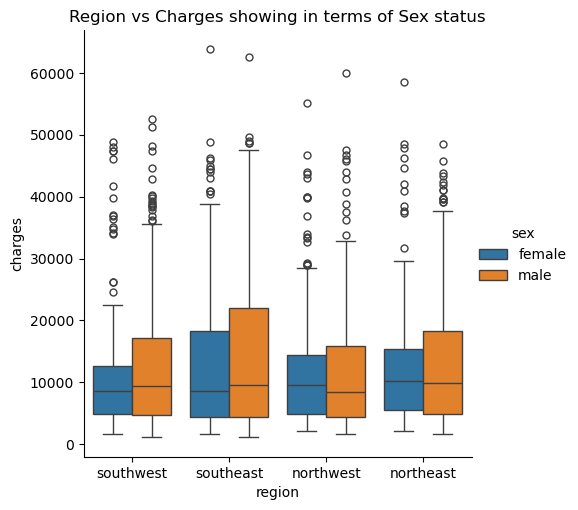

In [12]:
# Visualize box plots  (Waskom, 2024)
sns.catplot(data= df_insurance, x="region", y="charges", hue="sex", kind="box")
plt.title("Region vs Charges showing in terms of Sex status")

##### Conclusion: The box plot reveals that there is a slightly higher charges for males in the region.

Text(0.5, 1.0, 'Sex vs Charges showing in terms of Smoker status')

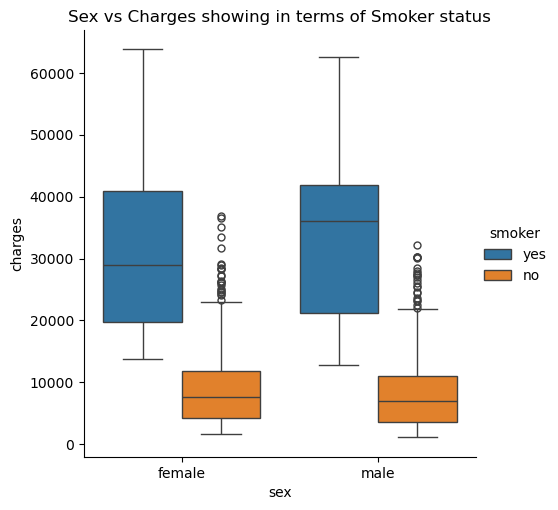

In [13]:
# Visualize box plots  (Waskom, 2024)
sns.catplot(data= df_insurance, x="sex", y="charges", hue="smoker", kind="box")
plt.title("Sex vs Charges showing in terms of Smoker status")

##### Conclusion: The box plot reveals that there are higher charges for smokers.

Text(0.5, 1.0, 'Region vs Charges showing in terms of Smoker status')

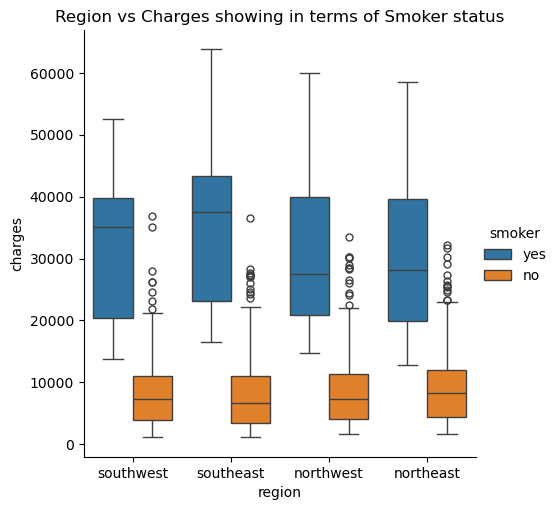

In [14]:
# Visualize box plots  (Waskom, 2024)
sns.catplot(data= df_insurance, x="region", y="charges", hue="smoker", kind="box")
plt.title("Region vs Charges showing in terms of Smoker status")

##### Conclusion: The box plot reveals that there are higher charges for smokers in the region.

##### **Categorical distributions**

In [15]:
# Distribution of categorical features
print("\nSex Distribution:\n", df_insurance["sex"].value_counts())
print("Conclusion: Sex Distribution shows that it is roughly balanced between male & female.")
print("\nSmoker Distribution:\n", df_insurance["smoker"].value_counts())
print("Conclusion: Smoker Distribution shows that minority are smokers (~20%).")
print("\nRegion Distribution:\n", df_insurance["region"].value_counts())
print("Conclusion: Region Distribution shows that it is fairly balanced across the four US regions.")


Sex Distribution:
 sex
male      676
female    662
Name: count, dtype: int64
Conclusion: Sex Distribution shows that it is roughly balanced between male & female.

Smoker Distribution:
 smoker
no     1064
yes     274
Name: count, dtype: int64
Conclusion: Smoker Distribution shows that minority are smokers (~20%).

Region Distribution:
 region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64
Conclusion: Region Distribution shows that it is fairly balanced across the four US regions.


Text(0.5, 1.0, 'Age Distribution')

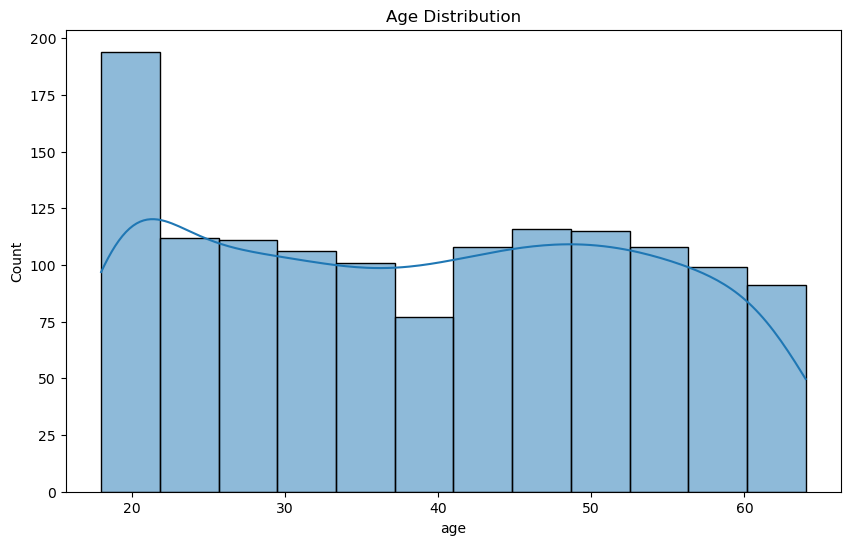

In [16]:
# Visualize distributions  (Waskom, 2024)
plt.figure(figsize=(10, 6))
sns.histplot(df_insurance["age"], kde=True)
plt.title("Age Distribution")

##### Conclusion: The histogram shows that "age" is uniformly distributed.

Text(0.5, 1.0, 'BMI Distribution')

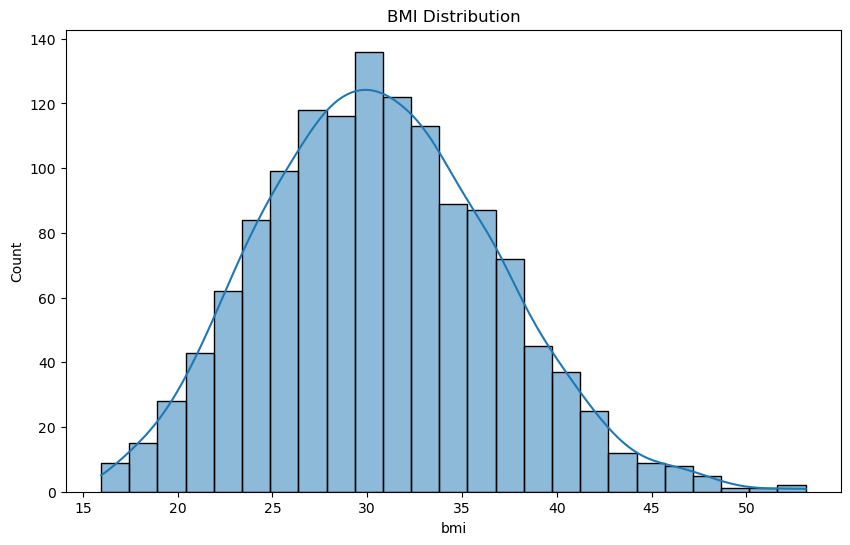

In [17]:
# Visualize distributions  (Waskom, 2024)
plt.figure(figsize=(10, 6))
sns.histplot(df_insurance["bmi"], kde=True)
plt.title("BMI Distribution")

##### Conclusion: The histogram shows that "BMI" is roughly normal.

Text(0.5, 1.0, 'Charges Distribution')

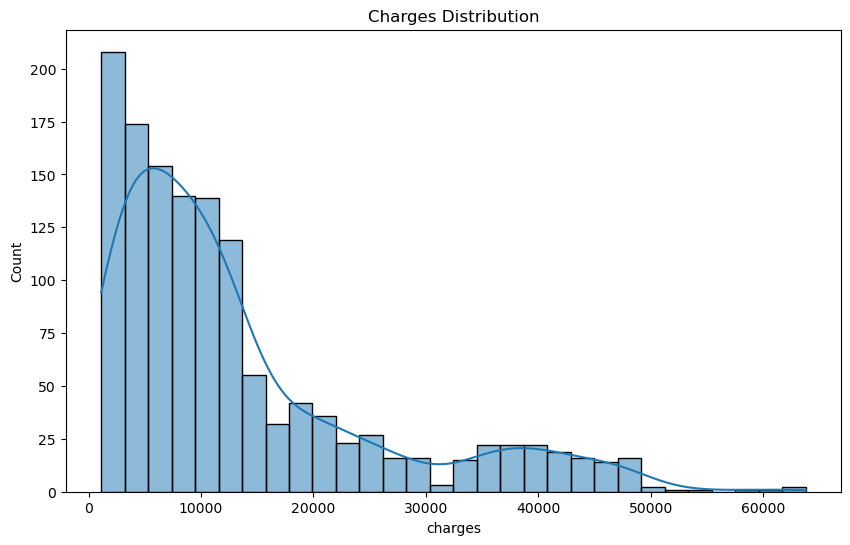

In [18]:
# Visualising the distributions (Waskom, 2024)
plt.figure(figsize=(10, 6))
sns.histplot(df_insurance["charges"], kde=True)
plt.title("Charges Distribution")

##### Conclusion: The histogram shows that "Charges" are right-skewed.

### Bivariate and Multivariate analysis

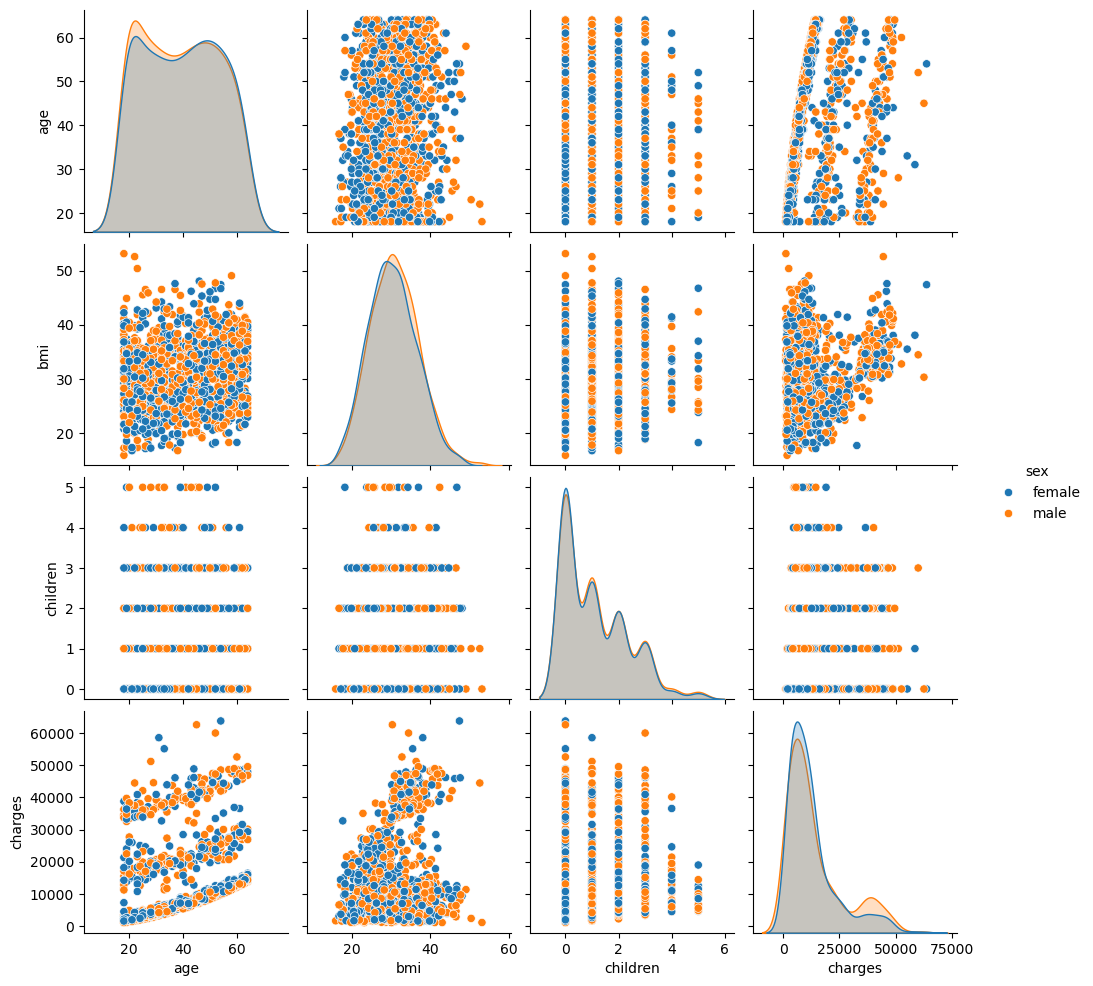

In [19]:
sns.pairplot(df_insurance, hue="sex")
# (IIEVC School of Computer Science, 2025)

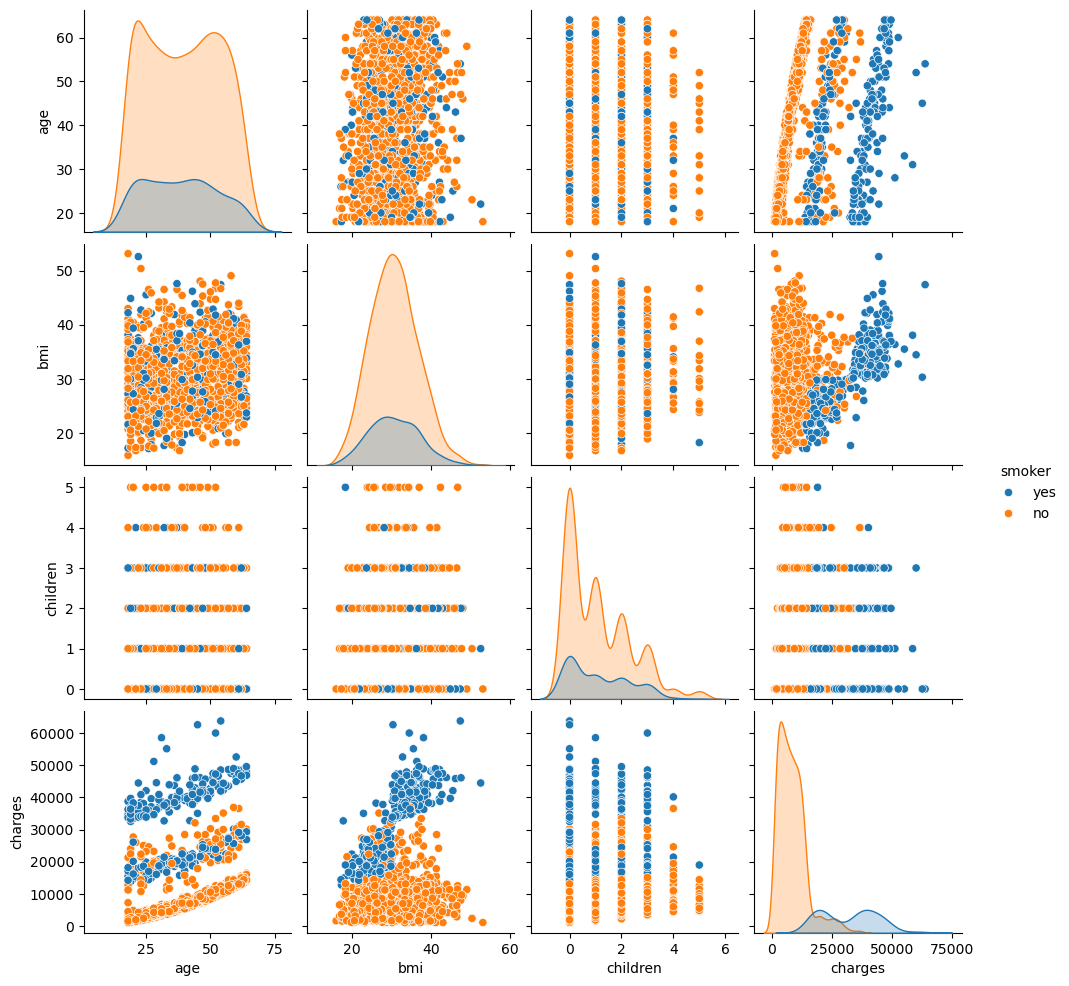

In [20]:
sns.pairplot(df_insurance, hue="smoker")
# (IIEVC School of Computer Science, 2025)

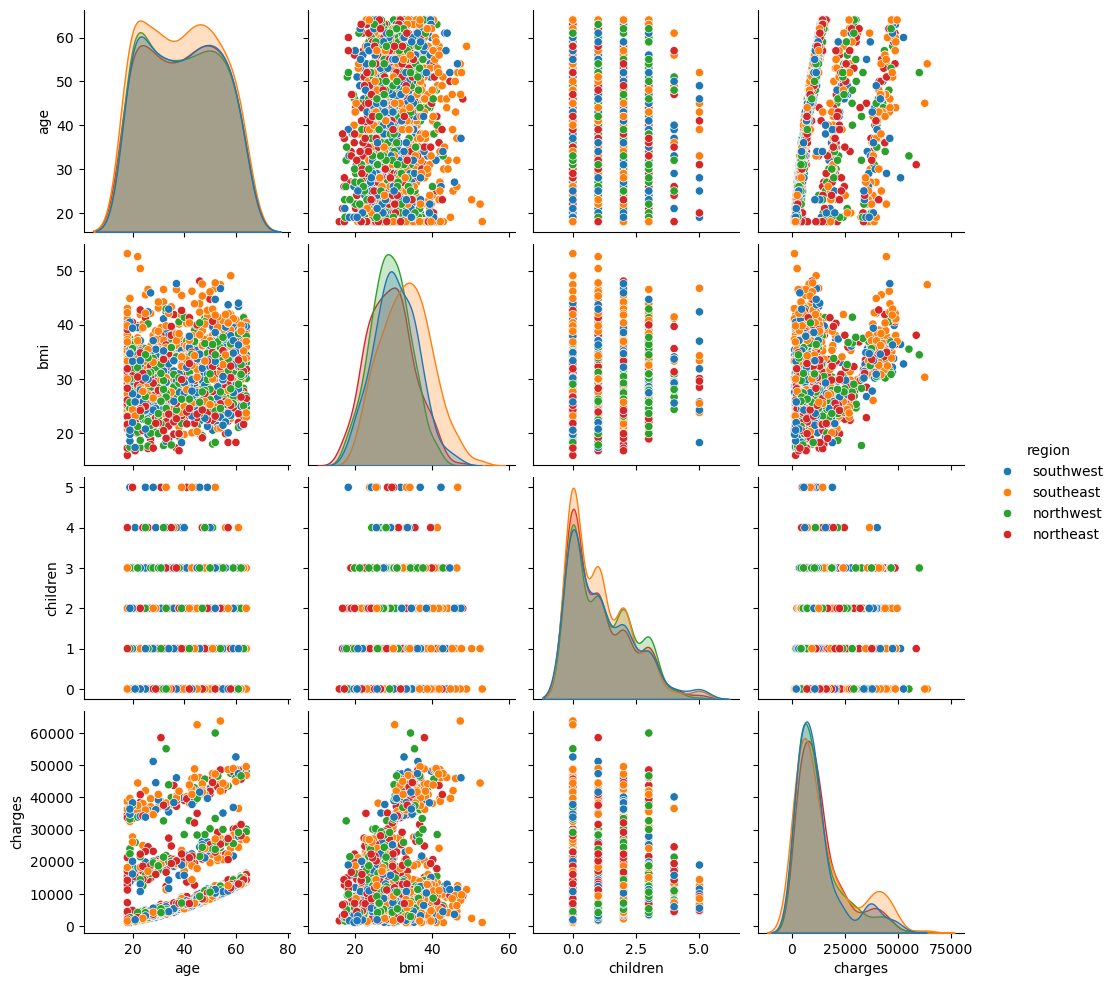

In [21]:
sns.pairplot(df_insurance, hue="region")
# (IIEVC School of Computer Science, 2025)

##### Observation: The pairplots of sex, smoker, and region have similarities, since they are categorical data.

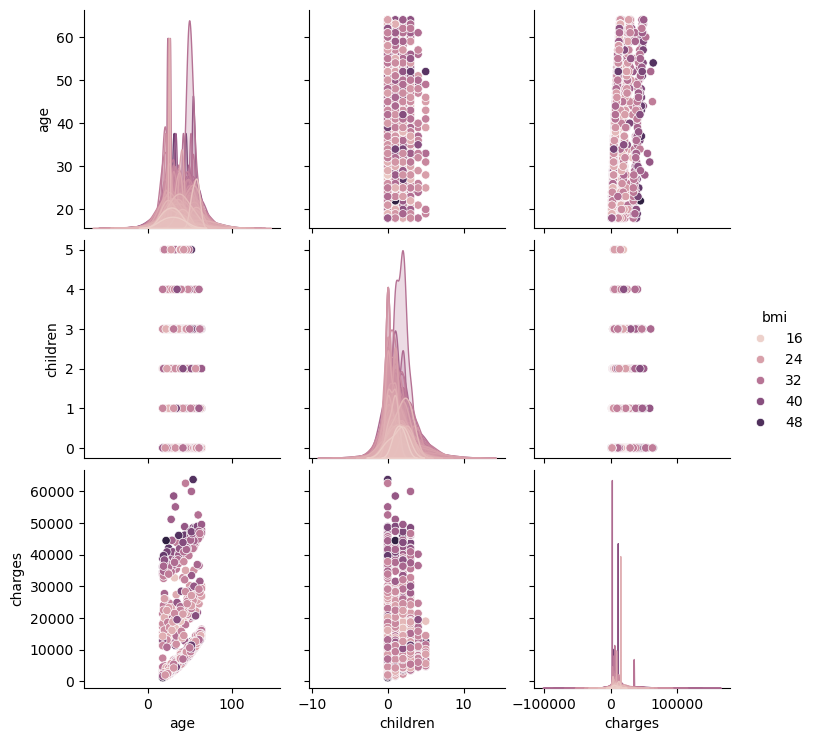

In [22]:
sns.pairplot(df_insurance, hue="bmi")
# (IIEVC School of Computer Science, 2025)

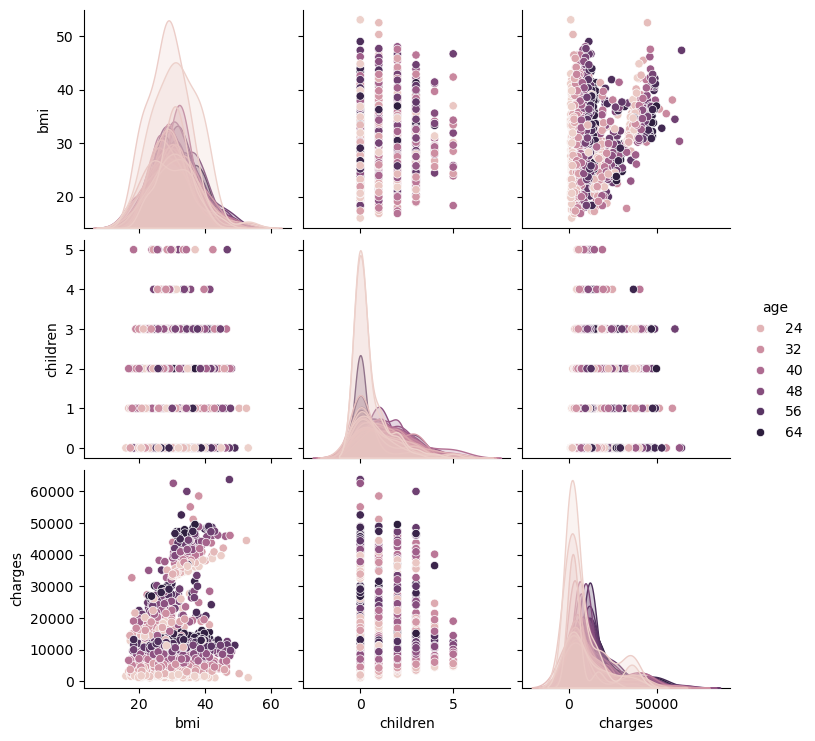

In [23]:
sns.pairplot(df_insurance, hue="age")
# (IIEVC School of Computer Science, 2025)

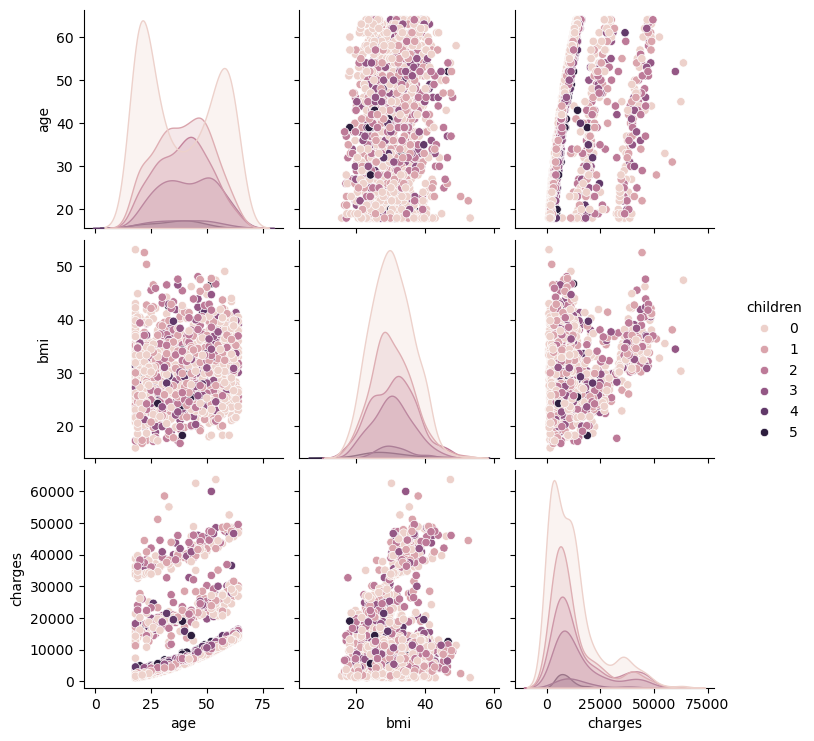

In [24]:
sns.pairplot(df_insurance, hue="children")
# (IIEVC School of Computer Science, 2025)

##### Observation: The pairplots of bmi, age, and children have similarities, since they are numerical data.

Text(0.5, 1.0, 'Age vs Charges')

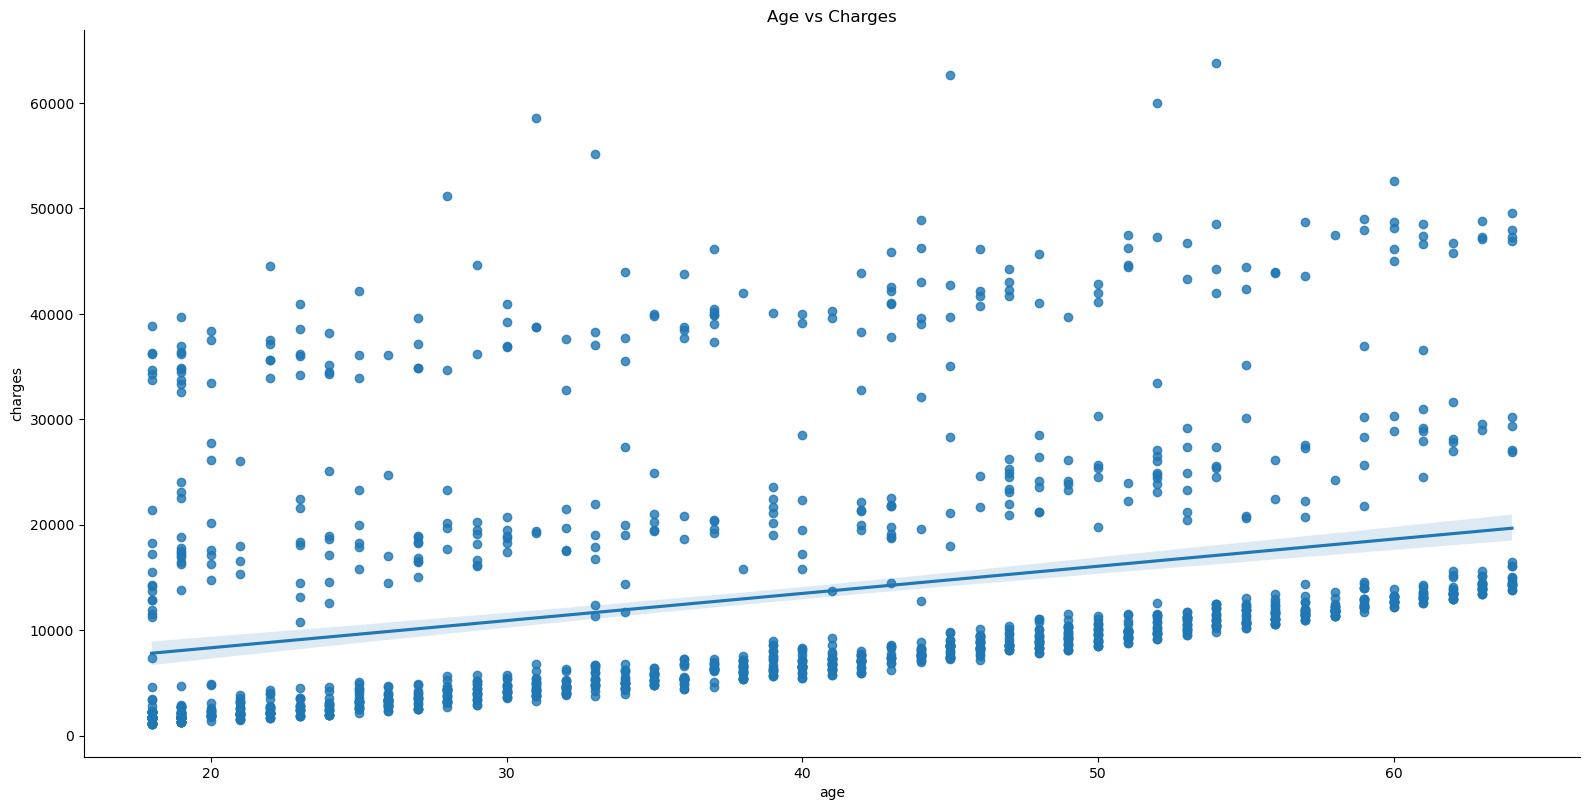

In [25]:
sns.lmplot(x='age',y='charges',data=df_insurance,aspect=2,height=8)
plt.title("Age vs Charges")
# (Kumar, 2020)

##### Age and charges shows a positive trend. 

#### **Correlations**

In [26]:
correlations = df_insurance.select_dtypes(include = "number").corr()
print(correlations)
print("\nCorrelation Analysis: \nAge has a strong correlation with Charges.")
print("BMI and children have weaker correlations.")
print("No strong multicollinearity among the features.")

               age       bmi  children   charges
age       1.000000  0.109272  0.042469  0.299008
bmi       0.109272  1.000000  0.012759  0.198341
children  0.042469  0.012759  1.000000  0.067998
charges   0.299008  0.198341  0.067998  1.000000

Correlation Analysis: 
Age has a strong correlation with Charges.
BMI and children have weaker correlations.
No strong multicollinearity among the features.


Text(0.5, 1.0, 'Correlation Matrix')

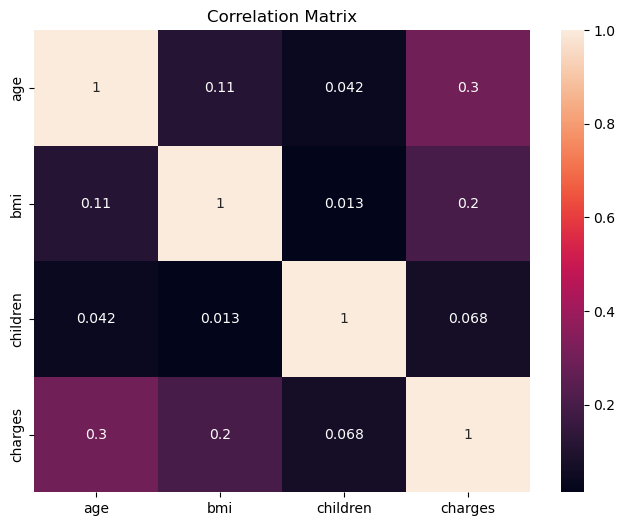

In [27]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True)
plt.title("Correlation Matrix")

#### **Cleaning the Dataset**

In [28]:
df_insurance.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [29]:
# Detects missing values
df_insurance.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [30]:
# Checking for total duplicated entries in the insurance DataFrame
df_insurance.duplicated().sum()

1

##### Found one duplicated entry

In [31]:
# Displaying which are the duplicated entries in the insurance DataFrame
duplicate_rows = df_insurance[df_insurance.duplicated()]
print("\nDuplicate Rows:")
print(duplicate_rows)


Duplicate Rows:
     age   sex    bmi  children smoker     region    charges
581   19  male  30.59         0     no  northwest  1639.5631


In [32]:
# Displaying the insurance DataFrame after removing duplicates
df_insurance_cleaned = df_insurance.drop_duplicates()
print("\nDataFrame after removing duplicates:")
print(df_insurance_cleaned)


DataFrame after removing duplicates:
      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1337 rows x 7 columns]


In [33]:
# Checking the number of unique values for each column in the insurance dataset:
print("\nUnique values for each column:")
df_insurance_cleaned.nunique()


Unique values for each column:


age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64

In [34]:
# Checking the dimensions of the cleaned insurance data
print("\nInsurance dataset dimensions:")
print(df_insurance_cleaned.shape)


Insurance dataset dimensions:
(1337, 7)


## **B. Feature Selection**

In [35]:
# This will convert categorical columns into multiple binary columns (0s and 1s)
# Encode categorical variables
df_insurance_cleaned = pd.get_dummies(df_insurance_cleaned, drop_first=True)

In [36]:
# The data columns after the encode convertion
df_insurance_cleaned.columns

Index(['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes',
       'region_northwest', 'region_southeast', 'region_southwest'],
      dtype='object')

Text(0.5, 1.0, 'Charges Distribution with Transormation')

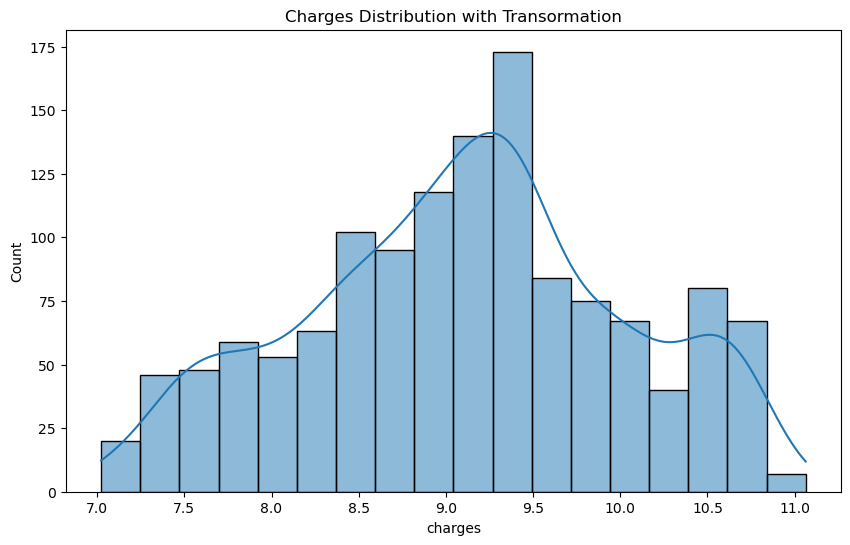

In [37]:
# Charges Distribution with Log Transormation 
y = np.log(df_insurance_cleaned["charges"])
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True)
plt.title("Charges Distribution with Transormation")

##### The histogram for "Charges Distribution" was skewed to the right, now I had applied a log transformation and transformed it so that it can be roughly normally distributed, which may improve residual normality.

In [38]:
# Check correlations with target
print("\nCorrelations with Charges:\n", df_insurance_cleaned.corr()["charges"].sort_values(ascending=False))
print("\nCorrelation Analysis: \nSmoker status has a strong correlation with Charges.")


Correlations with Charges:
 charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64

Correlation Analysis: 
Smoker status has a strong correlation with Charges.


##### Correlation of cleaned dataset

In [39]:
correlations_cleaned = df_insurance_cleaned.select_dtypes(include = "number").corr()
print(correlations_cleaned)

               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


Text(0.5, 1.0, 'Correlation Matrix')

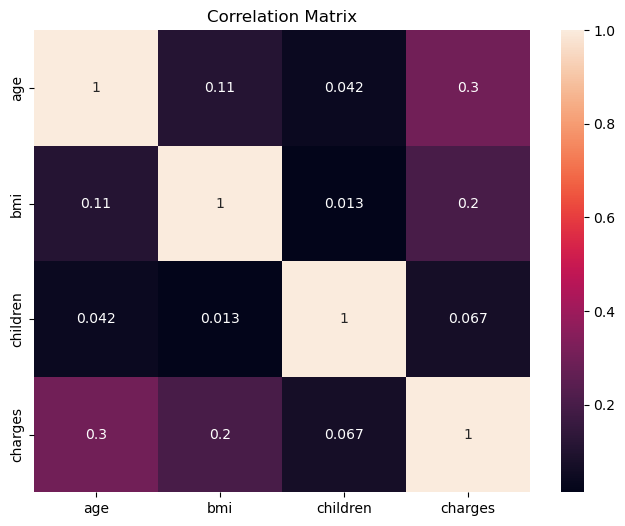

In [40]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlations_cleaned, annot=True)
plt.title("Correlation Matrix")

##### Observation: Only the children correlation was affected but the rest of the correlation remains the same as previously.

## **C. Train Model**

In [41]:
# Defining the features and the target
# x contains all the features (independent variables) by dropping the target variable charges
x = df_insurance_cleaned.drop("charges", axis=1)    # Features (independent variables)
y = df_insurance_cleaned["charges"]   # Target variable (dependent variable)
# (Kumar, 2020)

#### **Split the dataset**

In [42]:
from sklearn.model_selection import train_test_split

In [43]:
# Spliting the dataset
# 20% of the data is reserved for testing, and the random_state parameter ensures reproducibility
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

##### Data Splitting: 80% used for training, 20% used for testing this ensures robust evaluation.

#### **Standardize the features**

In [44]:
from sklearn.preprocessing import StandardScaler

In [45]:
# Standardize the features by removing the mean and scaling to unit variance
scaler = StandardScaler()   # Creates a StandardScaler object
x_train_scaled = scaler.fit_transform(x_train)   # Fit and transform the training data
x_test_scaled = scaler.transform(x_test)   # Transform the test data

#### **Linear Regression**

In [46]:
from sklearn.linear_model import LinearRegression

In [47]:
# Train Linear Regression model
model_lnrg = LinearRegression()  # Creates a LinearRegression object
model_lnrg.fit(x_train_scaled, y_train)  # Fit the model to the training data

LinearRegression()

# **4. Model Evaluation**

#### **Interpret and Evaluate Model**

In [48]:
# Evaluate the model
r_squared = model_lnrg.score(x_test_scaled, y_test)  # Evaluate using scaled test set
print(f"\nThe coefficient of determination is: {r_squared}")


The coefficient of determination is: 0.8069287081198013


##### The coefficient of determination (r_squared) is ~0.80 indicating that it is about 81% (when rounded off to 2 decimals) of the variability is explained, which is a stronger fit (Fernando, 2024). This means the r_squared model of 0.81 captures more of the underlying patterns in the data. It indicates a better fit and maybe more accurate predictions by explaining a larger percentage of the variance in the dependent variable (Fernando, 2024). 

#### **Predicting on the test set**

In [49]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [50]:
# Predicting on the test set
y_pred = model_lnrg.predict(x_test_scaled)  # Generate predictions using the test set
print(y_pred)

[ 8.14369388e+03  5.73711568e+03  1.43693149e+04  3.17455136e+04
  8.96238666e+03  1.31497224e+04  3.04467607e+04  1.45328881e+03
  1.06330184e+04  1.13189438e+04  1.03778536e+04  3.31184377e+04
  3.10772527e+04  1.74119253e+04  1.08016743e+04  9.52889964e+03
  4.16103784e+03  3.17315373e+04  3.21938875e+03  5.22992460e+03
  3.54979004e+03  3.02837740e+04  1.48989509e+04  3.04569093e+04
  3.11077668e+04  5.51196081e+03  3.55030401e+04  3.65704810e+04
  1.14123133e+04  1.42056990e+04  6.50234029e+03  1.27246945e+04
  3.99806590e+02  1.20883980e+04  3.96592069e+04  1.23395540e+04
  4.74412279e+03  3.91903157e+03  3.08606789e+04  8.95870663e+03
  7.05389441e+03  3.01125636e+04  3.47804324e+04  1.22916189e+04
  7.35739310e+03  3.42060530e+03  6.21243471e+03  8.98345200e+03
  4.26401828e+03  9.01992870e+03  6.60149578e+03  1.20802337e+04
  3.12447687e+04  3.55341947e+03  1.10470477e+04  9.73512492e+03
  1.08383403e+04  2.42942719e+03  3.11621909e+04  9.40578078e+03
  1.55793421e+04  8.19158

In [ ]:
# A DataFrame to compare actual and predicted values 
# (IIEVC School of Computer Science, 2025)
df_results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred.flatten()})
print(df_results)

           Actual     Predicted
900    8688.85885   8143.693884
1064   5708.86700   5737.115683
1256  11436.73815  14369.314876
298   38746.35510  31745.513636
237    4463.20510   8962.386657
...           ...           ...
534   13831.11520  16753.406458
542   13887.20400  15274.565769
760    3925.75820   6454.699355
1284  47403.88000  38467.156720
1285   8534.67180   8324.070599

[268 rows x 2 columns]


#### **Evaluation Metrics**

In [52]:
# Calculate evaluation metrics
rmse = root_mean_squared_error(y_test, y_pred).round(2)  # Calculate RMSE (Root Mean Squared Error)
mae = mean_absolute_error(y_test, y_pred).round(2)  # Calculate MAE (Mean Absolute Error"))
r2 = r2_score(y_test, y_pred).round(2)  # Calculate R-squared

# Print the results
print(f"\nRMSE: {rmse}")
print(f"\nMean Absolute Error: {mae}")
print(f"\nR-squared: {r2}")


RMSE: 5956.34

Mean Absolute Error: 4177.05

R-squared: 0.81


##### I used RMSE (Root mean squared error) instead of MSE (Mean squared error) since RMSE is more interpretable than MSE and both have the same function of measuring how well the regression model fits the data.

#### **Interpretation**

In [54]:
# Interpret intercept
print("\nModel intercept:\n", model_lnrg.intercept_.round(3))  # Display the intercept


Model intercept:
 13030.203


In [55]:
# Interpret coefficients
coefficients = pd.DataFrame(model_lnrg.coef_, x.columns, columns=["Coefficient"])  # Create a DataFrame for coefficients
print("\nModel Coefficients:\n", coefficients)  # Display the coefficients


Model Coefficients:
                   Coefficient
age               3472.975553
bmi               1927.828251
children           636.501185
sex_male           -50.749675
smoker_yes        9234.342487
region_northwest  -168.944439
region_southeast  -371.780810
region_southwest  -284.610396


##### P-values: Age, BMI, children, and smoker_yes = Feature Significance as these have a strong influence on medical costs.
##### P-values: sex_male, region_northwest, region_southeast, and region_southwest = Feature Non-Significant as these have a less influence on medical costs.


In [56]:
# Calculate residuals
residuals = y_test - y_pred  # Calculate the difference between actual and predicted values
print("\nResiduals: \n", residuals)


Residuals: 
 900      545.164966
1064     -28.248683
1256   -2932.576726
298     7000.841464
237    -4499.181557
           ...     
534    -2922.291258
542    -1387.361769
760    -2528.941155
1284    8936.723280
1285     210.601201
Name: charges, Length: 268, dtype: float64


In [57]:
# Residual statistic summary
residuals.describe()

count      268.000000
mean       425.256995
std       5952.258087
min     -10314.509078
25%      -2732.812019
50%       -906.863946
75%       1805.380287
max      24111.221121
Name: charges, dtype: float64

In [58]:
residuals.head(10)

900      545.164966
1064     -28.248683
1256   -2932.576726
298     7000.841464
237    -4499.181557
481    -3845.020453
240     8064.867621
277      697.180187
415    -3287.291802
707    -1054.501694
Name: charges, dtype: float64

In [59]:
from scipy.stats import probplot

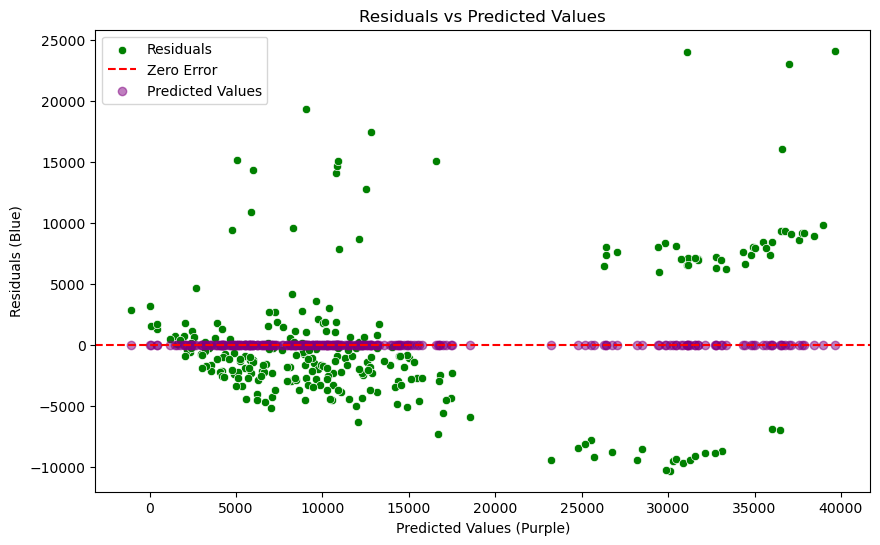

In [60]:
# Create a residual plot
plt.figure(figsize=(10, 6))  # Set the figure size
sns.scatterplot(x=y_pred, y=residuals, color="green", label="Residuals")  # Scatter plot of predicted values vs. residuals
plt.axhline(0, color="red", linestyle='--', label="Zero Error")  # Add a horizontal line at y=0 for reference
plt.title("Residuals vs Predicted Values")  # Title for the plot
plt.xlabel("Predicted Values (Purple)")  # Label for the x-axis
plt.ylabel("Residuals (Blue)")  # Label for the y-axis

# Overlay predicted values in purple
plt.scatter(y_pred, [0]*len(y_pred), color="purple", label="Predicted Values", alpha=0.5)  # Add predicted values as a separate scatter

plt.legend()  # Show legend
plt.show()  # Display the plot
# (Kumar, 2020)

Text(0.5, 1.0, 'Q-Q Plot of Residuals')

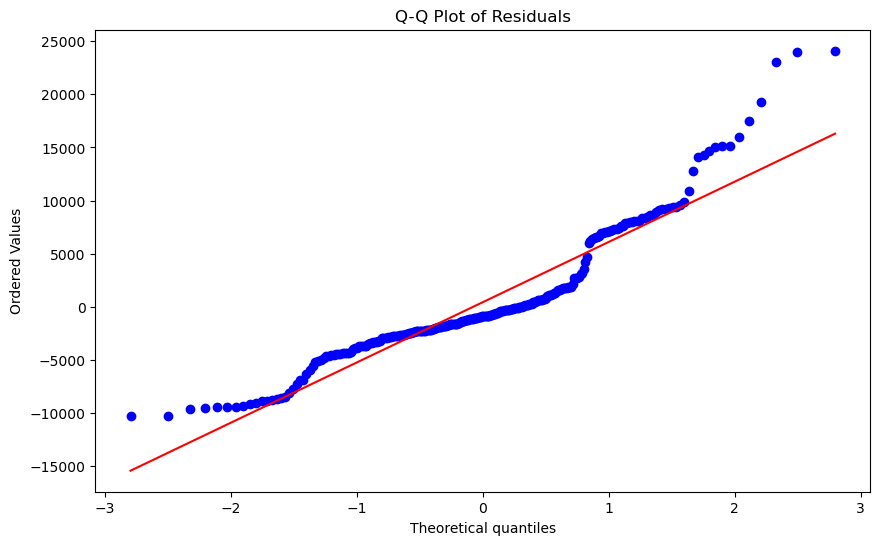

In [61]:
# Q-Q (Quantile-Quantile) plot for normality
# To visually check for distributional assumptions
plt.figure(figsize=(10, 6))
probplot(residuals, plot=plt)
plt.title("Q-Q Plot of Residuals")
# (Kumar, 2020)

#### The Q-Q plot likely shows significant deviations from normality, particularly in the tails due to extreme residuals, suggesting that the model for charges may not fully capture the data’s distribution or may be affected by outliers.

### **References**

##### Choi, M. 2018. Medical Cost Personal Datasets, *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/mirichoi0218/insurance [Accessed 20 April 2025].

##### Fernando, J. 2024. R-Squared: Definition, Calculation, and Interpretation, *Investopedia*, 13 November 2024. [Blog]. Available at: https://www.investopedia.com/terms/r/r-squared.asp [Accessed 23 April 2025].

##### IIEVC School of Computer Science. 2025. PDAN Tutorial 20250318 (Nadia), *YouTube*. [Online]. Available at: https://www.youtube.com/watch?v=1fCuLTMaXqo&list=PL480DYS-b_kfdTkMafoc6Q12x5sYTHkbz&index=5 [Accessed 22 April 2025].

##### Kumar, S. 2020. Linear Regression Tutorial, *Kaggle*. [Online]. Available at: https://www.kaggle.com/code/sudhirnl7/linear-regression-tutorial#Hypothesis-representation [Accessed 21 April 2025].


##### Waskom, M. 2024. Visualizing categorical of data, *Seaborn: Tutorial*. [Online]. Available at: https://seaborn.pydata.org/tutorial/categorical.html [Accessed 24 April 2025].

#####  Waskom, M. 2024. Visualizing distributions of data, *Seaborn: Tutorial*. [Online]. Available at: https://seaborn.pydata.org/tutorial/distributions.html [Accessed 24 April 2025].